## Configuration

In [1]:
from pathlib import Path
import json
import time

import pandas as pd
import requests
%matplotlib widget
import matplotlib.pyplot as plt

REPO = Path("/media/ata/Data/personal/binbot")
DATA_DIR = REPO / "research" / "sentiment_price" / "data"
CACHE_DIR = DATA_DIR / "btcusdt_5m_batches"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Warm-up before 2025 and a buffer for forward-return labels.
START = pd.Timestamp("2024-12-30", tz="UTC")
END = pd.Timestamp("2026-01-02", tz="UTC")  # exclusive

STEP_MS = 5 * 60 * 1000
START_MS = int(START.timestamp() * 1000)
END_MS = int(END.timestamp() * 1000)

print("Expected candles:", (END_MS - START_MS) // STEP_MS)

Expected candles: 105984


### Download, with resumable caching

In [2]:
all_candles = []
cursor = START_MS

with requests.Session() as session:
    while cursor < END_MS:
        batch_end = min(cursor + 1000 * STEP_MS, END_MS)
        cache_file = CACHE_DIR / f"{cursor}_{batch_end}.json"

        if cache_file.exists():
            batch = json.loads(cache_file.read_text())
        else:
            response = session.get(
                "https://api.binance.com/api/v3/klines",
                params={
                    "symbol": "BTCUSDT",
                    "interval": "5m",
                    "timeZone": "0",
                    "startTime": cursor,
                    "endTime": batch_end - 1,
                    "limit": 1000,
                },
                timeout=30,
            )
            response.raise_for_status()
            batch = response.json()

        if not isinstance(batch, list) or not batch:
            raise ValueError(f"Unexpected response at {cursor}: {batch}")

        # Require every expected candle; do not silently fill gaps.
        expected_opens = list(range(cursor, batch_end, STEP_MS))
        actual_opens = [int(row[0]) for row in batch]

        if actual_opens != expected_opens:
            raise ValueError(
                f"Missing, duplicate or unexpected candles in batch {cursor}"
            )

        if not cache_file.exists():
            temporary = cache_file.with_suffix(".tmp")
            temporary.write_text(json.dumps(batch))
            temporary.replace(cache_file)
            time.sleep(0.2)

        all_candles.extend(batch)
        cursor = batch_end

        print(
            f"\rLoaded {len(all_candles):,} candles",
            end="",
            flush=True,
        )

print("\nDownload/cache loading complete.")

Loaded 105,984 candles
Download/cache loading complete.


### Convert and validate

In [3]:
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trade_count",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(all_candles, columns=columns)

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric = [
    "open", "high", "low", "close", "volume", "quote_volume",
    "trade_count", "taker_buy_volume", "taker_buy_quote_volume",
]
bars[numeric] = bars[numeric].apply(pd.to_numeric, errors="raise")
bars = bars.set_index("open_time").sort_index()

expected_index = pd.date_range(
    START, END - pd.Timedelta(minutes=5), freq="5min"
)

assert bars.index.is_unique
assert bars.index.equals(expected_index), "Unexpected candle coverage"
assert bars[numeric].notna().all().all()
assert (bars[["open", "high", "low", "close"]] > 0).all().all()
assert (bars["low"] <= bars[["open", "close"]].min(axis=1)).all()
assert (bars["high"] >= bars[["open", "close"]].max(axis=1)).all()
assert (bars["volume"] >= 0).all()

print("Validated candles:", len(bars))
print("First candle:", bars.index.min())
print("Last candle:", bars.index.max())
display(bars[["open", "high", "low", "close", "volume"]].head())

Validated candles: 105984
First candle: 2024-12-30 00:00:00+00:00
Last candle: 2026-01-01 23:55:00+00:00


,open,high,low,close,volume
open_time,,,,,
2024-12-30 00:00:00+00:00,93738.19,93744.00,93510.00,93564.15,101.76638
2024-12-30 00:05:00+00:00,93564.15,93782.38,93557.60,93710.18,62.81994
2024-12-30 00:10:00+00:00,93710.18,93720.44,93593.80,93720.44,38.19082
2024-12-30 00:15:00+00:00,93720.43,93908.24,93645.78,93788.00,97.03277
2024-12-30 00:20:00+00:00,93788.01,93788.01,93586.95,93683.02,44.34342


### Compute price-relative features

In [4]:
# bars is indexed by candle OPEN time.
features = pd.DataFrame(index=bars.index)

# First candle's open for each UTC calendar day.
utc_day = bars.index.normalize()
day_open = bars["open"].groupby(utc_day).transform("first")

features["day_displacement_usdt"] = bars["close"] - day_open
features["day_return_pct"] = 100 * (bars["close"] / day_open - 1)

# Fixed-duration trailing returns, ending at the current candle close.
for hours in (1, 4, 12):
    periods = hours * 12  # twelve 5-minute candles per hour
    features[f"trailing_{hours}h_pct"] = (
        100 * (bars["close"] / bars["close"].shift(periods) - 1)
    )

# How much of the candle's UTC day has elapsed at decision time.
# The final candle has 24 hours elapsed; the next candle starts a new day.
decision_times = bars.index + pd.Timedelta(minutes=5)
features["hours_since_day_open"] = (
    (decision_times - utc_day) / pd.Timedelta(hours=1)
)

display(features.loc["2025-01-01"].head())

,day_displacement_usdt,day_return_pct,trailing_1h_pct,trailing_4h_pct,trailing_12h_pct,hours_since_day_open
open_time,,,,,,
2025-01-01 00:00:00+00:00,85.20,0.091049,0.260679,-0.457850,-0.885773,0.083333
2025-01-01 00:05:00+00:00,31.10,0.033235,-0.030854,-0.623202,-1.011593,0.166667
2025-01-01 00:10:00+00:00,80.18,0.085684,-0.060163,-0.308751,-0.775857,0.250000
2025-01-01 00:15:00+00:00,220.35,0.235477,0.141260,-0.182573,-0.640039,0.333333
2025-01-01 00:20:00+00:00,164.00,0.175259,0.109133,-0.336415,-0.976032,0.416667


### Plot a short interval

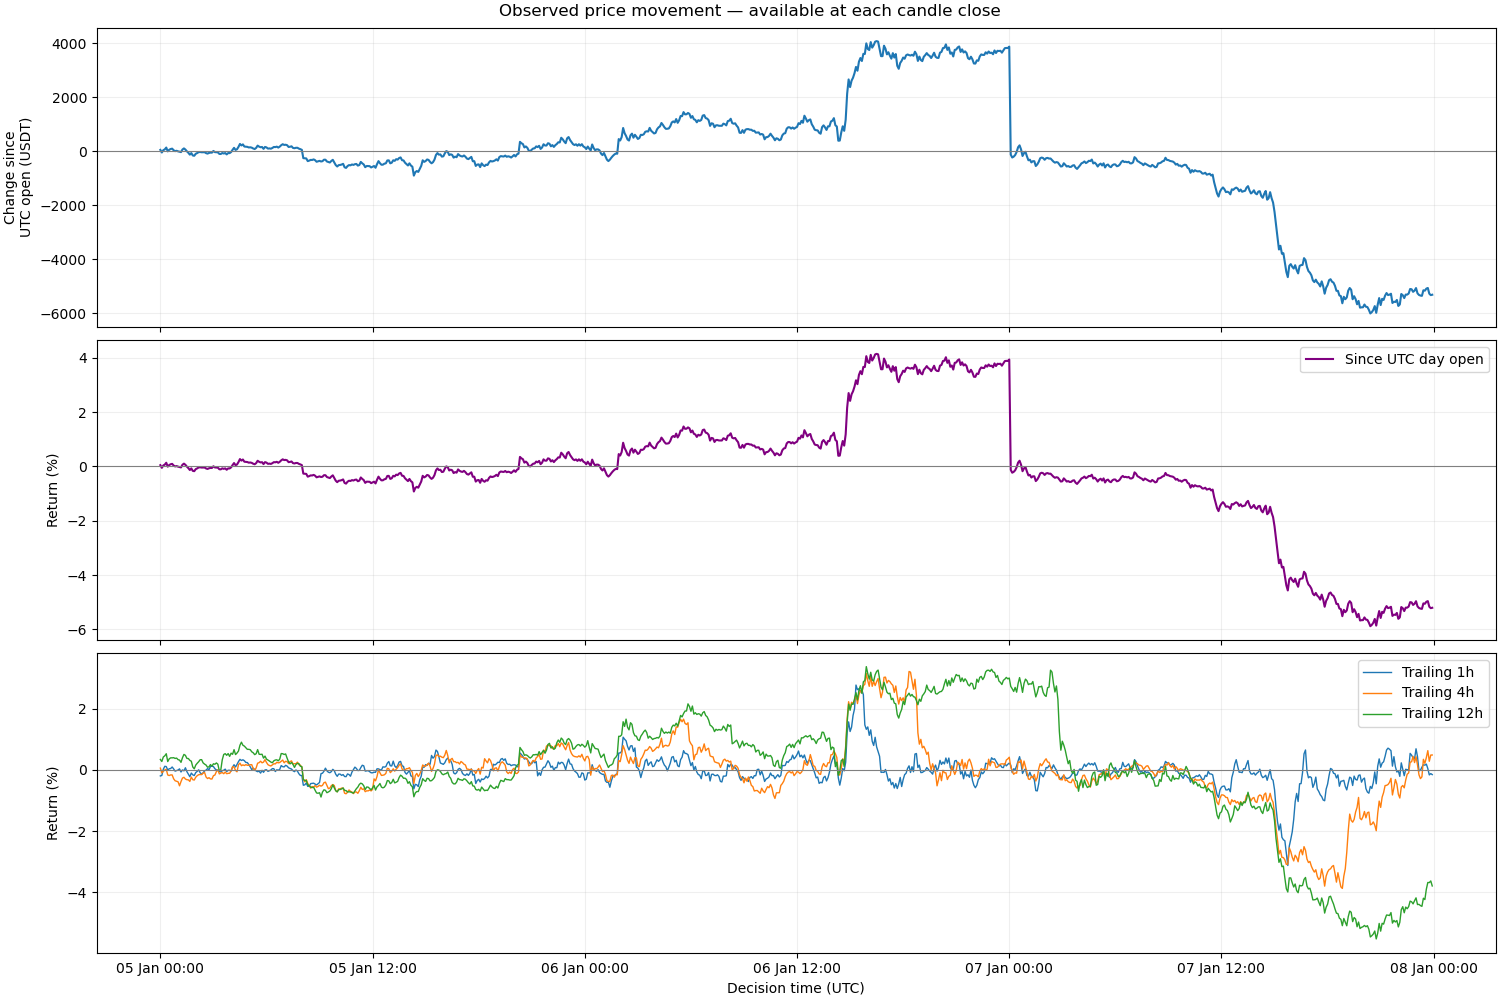

In [5]:
import matplotlib.pyplot as plt

PLOT_START = "2025-01-05"
PLOT_END = "2025-01-08"  # exclusive

start = pd.Timestamp(PLOT_START, tz="UTC")
end = pd.Timestamp(PLOT_END, tz="UTC")

# Display features at the time they become available.
feature_view = features.copy()
feature_view.index = decision_times
view = feature_view.loc[
    (feature_view.index >= start) & (feature_view.index < end)
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharex=True,
    constrained_layout=True,
)

axes[0].plot(view.index, view["day_displacement_usdt"])
axes[0].set_ylabel("Change since\nUTC open (USDT)")

axes[1].plot(
    view.index, view["day_return_pct"],
    label="Since UTC day open", color="purple",
)
axes[1].set_ylabel("Return (%)")
axes[1].legend()

for hours in (1, 4, 12):
    axes[2].plot(
        view.index,
        view[f"trailing_{hours}h_pct"],
        label=f"Trailing {hours}h",
        linewidth=1,
    )

axes[2].set_ylabel("Return (%)")
axes[2].set_xlabel("Decision time (UTC)")
axes[2].legend()

for ax in axes:
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.grid(alpha=0.2)
import matplotlib.dates as mdates
from datetime import timezone

axes[2].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b %H:%M", tz=timezone.utc)
)
fig.suptitle("Observed price movement — available at each candle close")
plt.show()

In [6]:
boundary = pd.DataFrame({
    "candle_open_utc": bars.index,
    "decision_utc": bars.index + pd.Timedelta(minutes=5),
    "reference_day": bars.index.normalize(),
    "day_open": day_open.to_numpy(),
    "candle_close": bars["close"].to_numpy(),
    "day_return_pct": features["day_return_pct"].to_numpy(),
})

is_boundary = (
    boundary["candle_open_utc"].dt.strftime("%H:%M")
    .isin(["23:55", "00:00"])
)

in_range = (
    boundary["candle_open_utc"].ge(pd.Timestamp("2025-01-05", tz="UTC"))
    & boundary["candle_open_utc"].lt(pd.Timestamp("2025-01-08", tz="UTC"))
)

display(boundary.loc[is_boundary & in_range].round(4))

,candle_open_utc,decision_utc,reference_day,day_open,candle_close,day_return_pct
1728,2025-01-05 00:00:00+00:00,2025-01-05 00:05:00+00:00,2025-01-05 00:00:00+00:00,98220.51,98170.67,-0.0507
2015,2025-01-05 23:55:00+00:00,2025-01-06 00:00:00+00:00,2025-01-05 00:00:00+00:00,98220.51,98363.61,0.1457
2016,2025-01-06 00:00:00+00:00,2025-01-06 00:05:00+00:00,2025-01-06 00:00:00+00:00,98363.61,98442.00,0.0797
2303,2025-01-06 23:55:00+00:00,2025-01-07 00:00:00+00:00,2025-01-06 00:00:00+00:00,98363.61,102235.60,3.9364
2304,2025-01-07 00:00:00+00:00,2025-01-07 00:05:00+00:00,2025-01-07 00:00:00+00:00,102235.60,102109.38,-0.1235
2591,2025-01-07 23:55:00+00:00,2025-01-08 00:00:00+00:00,2025-01-07 00:00:00+00:00,102235.60,96954.61,-5.1655


### Compute forward targets

In [7]:
targets = pd.DataFrame(index=bars.index)

entry_price = bars["open"].shift(-1)

for hours in (1, 4, 12):
    periods = hours * 12

    # Entry at t+1; exit exactly 'periods' candles after entry.
    exit_price = bars["open"].shift(-(periods + 1))

    targets[f"forward_{hours}h_pct"] = (
        100 * (exit_price / entry_price - 1)
    )

# Keep rows whose decision time falls within 2025.
decision_times = bars.index + pd.Timedelta(minutes=5)
in_2025 = (
    (decision_times >= pd.Timestamp("2025-01-01", tz="UTC"))
    & (decision_times < pd.Timestamp("2026-01-01", tz="UTC"))
)

feature_columns = [
    "day_return_pct",
    "trailing_1h_pct",
    "trailing_4h_pct",
    "trailing_12h_pct",
]

study = features[feature_columns].join(targets).loc[in_2025].copy()
study.index = decision_times[in_2025]
study.index.name = "decision_utc"

assert study.notna().all().all(), "Unexpected missing features or targets"

print("Decision rows:", len(study))
display(study.head())

Decision rows: 105120


,day_return_pct,trailing_1h_pct,trailing_4h_pct,trailing_12h_pct,forward_1h_pct,forward_4h_pct,forward_12h_pct
decision_utc,,,,,,,
2025-01-01 00:00:00+00:00,0.844846,0.093230,-0.627482,-0.696871,0.881775,0.280029,-0.140367
2025-01-01 00:05:00+00:00,0.091049,0.260679,-0.457850,-0.885773,0.488153,0.146016,-0.171608
2025-01-01 00:10:00+00:00,0.033235,-0.030854,-0.623202,-1.011593,0.485337,0.128484,-0.132896
2025-01-01 00:15:00+00:00,0.085684,-0.060163,-0.308751,-0.775857,0.530504,0.058715,-0.218694
2025-01-01 00:20:00+00:00,0.235477,0.141260,-0.182573,-0.640039,0.206703,-0.096603,-0.268283


### Compare features with future returns

In [8]:
rows = []

for hours in (1, 4, 12):
    target = f"forward_{hours}h_pct"

    # Fixed UTC schedule: hourly, every four hours, or every twelve hours.
    scheduled = (
        (study.index.minute == 0)
        & (study.index.hour % hours == 0)
    )

    for sample_name, sample in [
        ("Every 5 minutes", study),
        ("Non-overlapping", study.loc[scheduled]),
    ]:
        for feature in feature_columns:
            pair = sample[[feature, target]].dropna()
            x, y = pair[feature], pair[target]

            rows.append({
                "sample": sample_name,
                "feature": feature,
                "forward_hours": hours,
                "observations": len(pair),
                "pearson": x.corr(y),
                "spearman": x.rank().corr(y.rank()),
            })

feature_correlations = pd.DataFrame(rows)

for sample_name in ["Every 5 minutes", "Non-overlapping"]:
    print(f"\n{sample_name}")
    display(
        feature_correlations.loc[
            feature_correlations["sample"].eq(sample_name)
        ].set_index(["feature", "forward_hours"]).round(4)
    )


Every 5 minutes


,,sample,observations,pearson,spearman
feature,forward_hours,,,,
day_return_pct,1,Every 5 minutes,105120,-0.0209,-0.0247
trailing_1h_pct,1,Every 5 minutes,105120,-0.0123,-0.0242
trailing_4h_pct,1,Every 5 minutes,105120,0.0118,-0.0102
trailing_12h_pct,1,Every 5 minutes,105120,-0.0086,-0.0211
day_return_pct,4,Every 5 minutes,105120,-0.0449,-0.0482
trailing_1h_pct,4,Every 5 minutes,105120,0.0119,-0.0125
trailing_4h_pct,4,Every 5 minutes,105120,0.0129,-0.0056
trailing_12h_pct,4,Every 5 minutes,105120,-0.0223,-0.0337
day_return_pct,12,Every 5 minutes,105120,-0.0905,-0.0832



Non-overlapping


,,sample,observations,pearson,spearman
feature,forward_hours,,,,
day_return_pct,1,Non-overlapping,8760,-0.0249,-0.0349
trailing_1h_pct,1,Non-overlapping,8760,-0.0135,-0.0322
trailing_4h_pct,1,Non-overlapping,8760,0.0064,-0.0235
trailing_12h_pct,1,Non-overlapping,8760,-0.0084,-0.0246
day_return_pct,4,Non-overlapping,2190,-0.0527,-0.0598
trailing_1h_pct,4,Non-overlapping,2190,0.0345,-0.0062
trailing_4h_pct,4,Non-overlapping,2190,0.0138,-0.0197
trailing_12h_pct,4,Non-overlapping,2190,-0.0230,-0.0411
day_return_pct,12,Non-overlapping,730,-0.0972,-0.0881


### Compute the measurements

In [9]:
import numpy as np

breakout_data = pd.DataFrame(index=bars.index)

# Exclude the current candle from the reference range.
breakout_data["prior_12h_high"] = (
    bars["high"].shift(1).rolling(144, min_periods=144).max()
)

above_range = bars["close"] > breakout_data["prior_12h_high"]

# First above-range close after a candle that was not above its range.
breakout_data["candidate"] = (
    above_range & ~above_range.shift(1, fill_value=False)
)

# Latest hour: current closed candle plus the preceding 11 candles.
hour_volume = bars["volume"].rolling(12, min_periods=12).sum()
hour_buy_volume = (
    bars["taker_buy_volume"].rolling(12, min_periods=12).sum()
)

breakout_data["trade_imbalance_1h"] = (
    (2 * hour_buy_volume - hour_volume)
    / hour_volume.where(hour_volume > 0)
)

# Baseline ends BEFORE the latest hour, so the windows do not overlap.
baseline_hourly_volume = (
    bars["volume"].shift(12).rolling(288, min_periods=288).sum() / 24
)

breakout_data["relative_volume_1h"] = (
    hour_volume / baseline_hourly_volume.where(baseline_hourly_volume > 0)
)

breakout_data["breakout_distance_pct"] = 100 * (
    bars["close"] / breakout_data["prior_12h_high"] - 1
)

# Four hours = 48 five-minute candles.
breakout_data["entry_price"] = bars["open"].shift(-1)
breakout_data["exit_price"] = bars["open"].shift(-49)
breakout_data["forward_4h_pct"] = 100 * (
    breakout_data["exit_price"] / breakout_data["entry_price"] - 1
)

# From here onward, the index denotes decision/nominal entry time.
breakout_data.index = bars.index + pd.Timedelta(minutes=5)
breakout_data.index.name = "decision_utc"

### Select non-overlapping events

In [10]:
in_year = (
    (breakout_data.index >= pd.Timestamp("2025-01-01", tz="UTC"))
    & (breakout_data.index < pd.Timestamp("2026-01-01", tz="UTC"))
)

required_features = [
    "prior_12h_high",
    "trade_imbalance_1h",
    "relative_volume_1h",
    "breakout_distance_pct",
]

candidates = breakout_data.loc[
    in_year & breakout_data["candidate"]
].dropna(subset=required_features)

selected_times = []
next_allowed = pd.Timestamp("2025-01-01", tz="UTC")

for timestamp in candidates.index:
    if timestamp >= next_allowed:
        selected_times.append(timestamp)
        next_allowed = timestamp + pd.Timedelta(hours=4)

events = candidates.loc[selected_times].copy()

assert events["forward_4h_pct"].notna().all()
assert np.isfinite(
    events[required_features + ["forward_4h_pct"]].to_numpy()
).all()

# Simple fixed groups; no threshold search.
events["buy_dominant"] = events["trade_imbalance_1h"] > 0
events["above_normal_volume"] = events["relative_volume_1h"] > 1

print("Breakout candidates:", len(candidates))
print("Selected non-overlapping events:", len(events))

display(events[
    [
        "trade_imbalance_1h",
        "relative_volume_1h",
        "breakout_distance_pct",
        "forward_4h_pct",
    ]
].head())

Breakout candidates: 1286
Selected non-overlapping events: 498


,trade_imbalance_1h,relative_volume_1h,breakout_distance_pct,forward_4h_pct
decision_utc,,,,
2025-01-01 14:05:00+00:00,0.249565,0.694984,0.283300,-0.358688
2025-01-01 19:50:00+00:00,0.104300,1.088043,0.256529,-0.105022
2025-01-02 00:50:00+00:00,0.000179,2.628675,0.126261,0.626782
2025-01-02 08:55:00+00:00,0.184512,1.306842,0.104081,0.698045
2025-01-02 16:35:00+00:00,0.059109,2.337981,0.095063,-0.004327


### Compare outcomes

In [11]:
def summarize_returns(frame):
    r = frame["forward_4h_pct"]
    return pd.Series({
        "events": len(r),
        "mean_return_pct": r.mean(),
        "median_return_pct": r.median(),
        "positive_return_pct": 100 * r.gt(0).mean(),
        "p10_return_pct": r.quantile(0.10),
        "p90_return_pct": r.quantile(0.90),
    })

print("All selected breakouts")
display(summarize_returns(events).to_frame("value").round(3))

group_rows = []

for (buy_dominant, high_volume), group in events.groupby(
    ["buy_dominant", "above_normal_volume"]
):
    row = summarize_returns(group).to_dict()
    row["trade_flow"] = (
        "Buy-dominant" if buy_dominant else "Sell-dominant or balanced"
    )
    row["volume"] = (
        "Above trailing baseline" if high_volume else "At/below trailing baseline"
    )
    group_rows.append(row)

breakout_summary = pd.DataFrame(group_rows)

display(
    breakout_summary.set_index(["trade_flow", "volume"]).round(3)
)

All selected breakouts


,value
events,498.000
mean_return_pct,-0.007
median_return_pct,-0.042
positive_return_pct,45.984
p10_return_pct,-1.013
p90_return_pct,0.999


events  mean_return_pct  \
trade_flow                volume                                                
Sell-dominant or balanced At/below trailing baseline    57.0            0.045   
                          Above trailing baseline       35.0            0.115   
Buy-dominant              At/below trailing baseline   188.0           -0.061   
                          Above trailing baseline      218.0            0.007   

                                                      median_return_pct  \
trade_flow                volume                                          
Sell-dominant or balanced At/below trailing baseline             -0.041   
                          Above trailing baseline                 0.064   
Buy-dominant              At/below trailing baseline             -0.061   
                          Above trailing baseline                -0.045   

                                                      positive_return_pct  \
trade_flow                volume                                            
Sell-dominant or balanced At/below trailing baseline               42.105   
                          Above trailing baseline                  51.429   
Buy-dominant              At/below trailing baseline               45.745   
                          Above trailing baseline                  46.330   

                                                      p10_return_pct  \
trade_flow                volume                                       
Sell-dominant or balanced At/below trailing baseline          -0.552   
                          Above trailing baseline             -0.927   
Buy-dominant              At/below trailing baseline          -0.925   
                          Above trailing baseline             -1.156   

                                                      p90_return_pct  
trade_flow                volume                                      
Sell-dominant or balanced At/below trailing baseline           0.930  
                          Above trailing baseline              0.945  
Buy-dominant              At/below trailing baseline           0.923  
                          Above trailing baseline              1.210

### Attach previous-day sentiment

In [12]:
sentiment_path = (
    REPO / "btc-sentiment-free" / "full_v3_runtime" / "daily.csv"
)

daily_news = pd.read_csv(sentiment_path)
daily_news["date_utc"] = pd.to_datetime(daily_news["date_utc"], utc=True)
daily_news = daily_news.set_index("date_utc").sort_index()

assert daily_news.index.is_unique

# Exact previous calendar day; do not carry older scores across missing days.
previous_day = events.index.normalize() - pd.Timedelta(days=1)
matched_news = daily_news.reindex(previous_day)

events_news = events.copy()
events_news["previous_day_sentiment"] = (
    matched_news["sentiment_score"].to_numpy()
)
events_news["previous_day_articles"] = (
    matched_news["usable_articles"].to_numpy()
)

score = events_news["previous_day_sentiment"]

events_news["sentiment_group"] = np.select(
    [score.gt(0), score.lt(0), score.eq(0)],
    ["Positive", "Negative", "Zero"],
    default="Missing",
)

assert len(events_news) == len(events)

### Compare the same events by sentiment

In [13]:
rows = []

for name, group in events_news.groupby("sentiment_group"):
    row = summarize_returns(group).to_dict()
    row["sentiment_group"] = name

    # Multiple events can share the same daily sentiment observation.
    row["distinct_entry_days"] = group.index.normalize().nunique()
    rows.append(row)

sentiment_breakout_summary = (
    pd.DataFrame(rows)
    .set_index("sentiment_group")
    .reindex(["Positive", "Negative", "Zero", "Missing"])
)

display(sentiment_breakout_summary.round(3))

,events,mean_return_pct,median_return_pct,positive_return_pct,p10_return_pct,p90_return_pct,distinct_entry_days
sentiment_group,,,,,,,
Positive,221.0,-0.026,-0.040,47.059,-1.060,1.073,128
Negative,86.0,0.080,-0.045,46.512,-0.938,1.086,47
Zero,93.0,-0.066,-0.147,39.785,-1.088,0.970,56
Missing,98.0,0.017,-0.004,48.980,-0.894,0.792,54


In [14]:
### Construct completed hourly candles and setup candidates

In [15]:
hourly = bars.resample(
    "1h", closed="left", label="right", origin="start_day"
).agg({
    "open": "first",
    "high": "max",
    "low": "min",
    "close": "last",
    "volume": "sum",
})

hour_counts = bars["close"].resample(
    "1h", closed="left", label="right", origin="start_day"
).count()

assert hour_counts.eq(12).all(), "Incomplete hourly candles"

hourly["prior_12h_high"] = (
    hourly["high"].shift(1).rolling(12, min_periods=12).max()
)

above = hourly["close"] > hourly["prior_12h_high"]
hourly["setup_candidate"] = above & ~above.shift(1, fill_value=False)

in_2025 = (
    (hourly.index >= pd.Timestamp("2025-01-01", tz="UTC"))
    & (hourly.index < pd.Timestamp("2026-01-01", tz="UTC"))
)

setup_candidates = hourly.loc[in_2025 & hourly["setup_candidate"]].copy()

# For this descriptive study, avoid overlapping observation windows.
# This is not an eventual trading/re-entry rule.
setup_times = []
next_allowed = pd.Timestamp("2025-01-01", tz="UTC")

for timestamp in setup_candidates.index:
    if timestamp >= next_allowed:
        setup_times.append(timestamp)
        next_allowed = timestamp + pd.Timedelta(hours=4)

setups = setup_candidates.loc[setup_times].copy()
setups.index.name = "setup_time_utc"

print("Hourly candidates:", len(setup_candidates))
print("Selected setup windows:", len(setups))

Hourly candidates: 430
Selected setup windows: 366


In [16]:
### Compute paths relative to setup activation

In [17]:
WINDOW_BARS = 48  # four hours of five-minute candles
minutes = np.arange(WINDOW_BARS + 1) * 5

path_rows = []

for timestamp in setups.index:
    expected = pd.date_range(
        timestamp, periods=WINDOW_BARS, freq="5min"
    )
    window = bars.reindex(expected)

    assert window[["open", "close"]].notna().all().all(), (
        f"Incomplete window at {timestamp}"
    )

    anchor = window["open"].iloc[0]

    path = np.concatenate([
        [0.0],
        100 * (window["close"].to_numpy() / anchor - 1),
    ])
    path_rows.append(path)

paths = pd.DataFrame(
    path_rows,
    index=setups.index,
    columns=minutes,
)
paths.columns.name = "minutes_after_setup"

print("Path matrix:", paths.shape)
display(paths.iloc[:5, ::12].round(3))

Path matrix: (366, 49)


minutes_after_setup,0,60,120,180,240
setup_time_utc,,,,,
2025-01-01 15:00:00+00:00,0.0,0.273,-0.091,-0.034,0.174
2025-01-01 20:00:00+00:00,0.0,0.168,0.371,0.186,-0.037
2025-01-02 05:00:00+00:00,0.0,-0.117,-0.139,0.119,0.462
2025-01-02 09:00:00+00:00,0.0,0.630,0.580,0.606,0.728
2025-01-02 15:00:00+00:00,0.0,-0.824,-0.027,-0.513,0.065


In [18]:
### Plot individual examples and the distribution

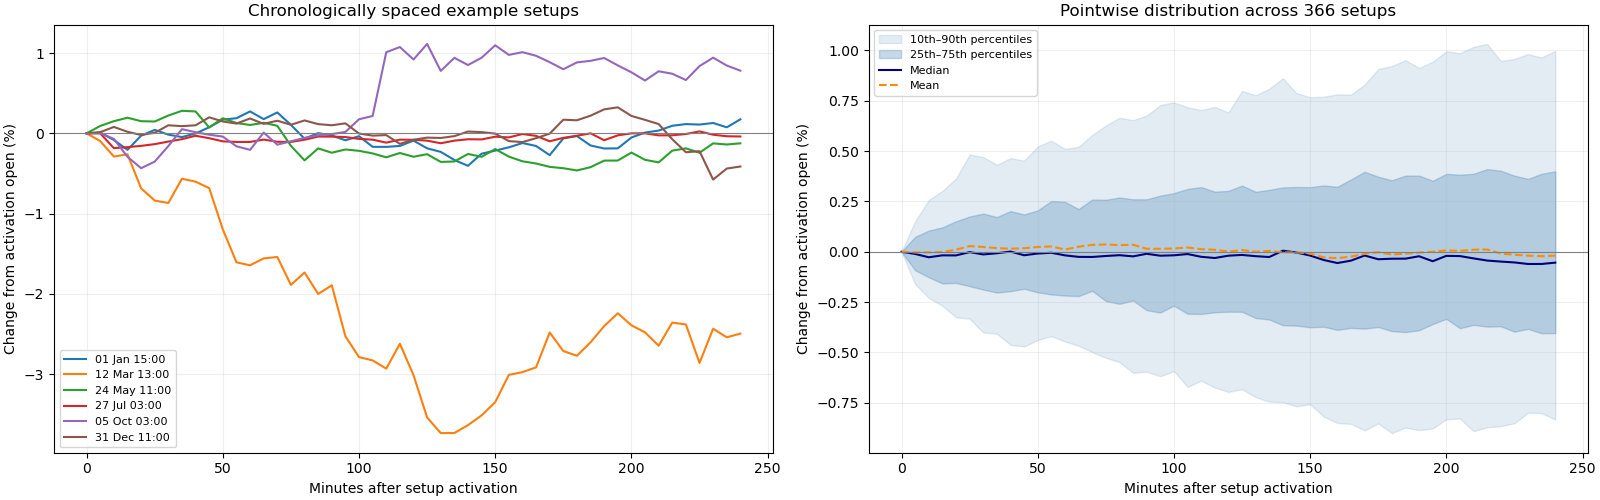

In [19]:
fig, axes = plt.subplots(
    1, 2, figsize=(16, 5), constrained_layout=True
)

example_positions = np.unique(
    np.linspace(0, len(paths) - 1, min(6, len(paths))).astype(int)
)

for position in example_positions:
    timestamp = paths.index[position]
    axes[0].plot(
        minutes,
        paths.iloc[position],
        label=timestamp.strftime("%d %b %H:%M"),
    )

axes[0].set_title("Chronologically spaced example setups")
axes[0].legend(fontsize=8)

quantiles = paths.quantile([0.10, 0.25, 0.50, 0.75, 0.90])

axes[1].fill_between(
    minutes, quantiles.loc[0.10], quantiles.loc[0.90],
    alpha=0.15, color="steelblue", label="10th–90th percentiles",
)
axes[1].fill_between(
    minutes, quantiles.loc[0.25], quantiles.loc[0.75],
    alpha=0.30, color="steelblue", label="25th–75th percentiles",
)
axes[1].plot(
    minutes, quantiles.loc[0.50],
    color="navy", label="Median",
)
axes[1].plot(
    minutes, paths.mean(),
    color="darkorange", linestyle="--", label="Mean",
)
axes[1].set_title(f"Pointwise distribution across {len(paths)} setups")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel("Minutes after setup activation")
    ax.set_ylabel("Change from activation open (%)")
    ax.grid(alpha=0.2)

plt.show()

In [20]:
### Construct ordinary four-hour windows

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ordinary_starts = pd.date_range(
    "2025-01-01",
    "2026-01-01",
    freq="4h",
    inclusive="left",
    tz="UTC",
)

ordinary_rows = []

for timestamp in ordinary_starts:
    expected = pd.date_range(timestamp, periods=48, freq="5min")
    window = bars.reindex(expected)

    assert window[["open", "close"]].notna().all().all(), timestamp

    anchor = window["open"].iloc[0]

    ordinary_rows.append(
        np.r_[0.0, 100 * (window["close"].to_numpy() / anchor - 1)]
    )

ordinary_paths = pd.DataFrame(
    ordinary_rows,
    index=ordinary_starts,
    columns=paths.columns,
)

print("Setup windows:", len(paths))
print("Ordinary windows:", len(ordinary_paths))

Setup windows: 366
Ordinary windows: 2190


In [22]:
### Measure what happened inside each window

In [23]:
def describe_paths(path_frame):
    result = pd.DataFrame(index=path_frame.index)

    result["final_return_pct"] = path_frame.iloc[:, -1]
    result["upward_excursion_pct"] = path_frame.max(axis=1)
    result["downward_excursion_pct"] = path_frame.min(axis=1)

    result["giveback_from_peak_pp"] = (
        result["upward_excursion_pct"] - result["final_return_pct"]
    )

    return result


setup_metrics = describe_paths(paths)
ordinary_metrics = describe_paths(ordinary_paths)

comparison = pd.concat(
    {
        "Setup": setup_metrics.agg(["mean", "median"]).T,
        "Ordinary": ordinary_metrics.agg(["mean", "median"]).T,
    },
    axis=1,
)

display(comparison.round(3))

display(pd.DataFrame({
    "windows": [len(setup_metrics), len(ordinary_metrics)],
    "positive_final_pct": [
        100 * setup_metrics["final_return_pct"].gt(0).mean(),
        100 * ordinary_metrics["final_return_pct"].gt(0).mean(),
    ],
}, index=["Setup", "Ordinary"]).round(2))

Setup        Ordinary       
                         mean median     mean median
final_return_pct       -0.019 -0.054    0.001  0.009
upward_excursion_pct    0.593  0.371    0.552  0.365
downward_excursion_pct -0.602 -0.380   -0.582 -0.359
giveback_from_peak_pp   0.613  0.449    0.551  0.354

,windows,positive_final_pct
Setup,366,46.17
Ordinary,2190,50.46


## compute candles and bands (bollinger indicator)

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def bollinger_bands(
    bars,
    start,
    end,
    resolution="1D",
    window=20,
    num_std=2.0,
):
    """
    Input:
        bars: 5-minute OHLCV, indexed by candle OPEN time.
        start: inclusive UTC timestamp.
        end: exclusive UTC timestamp.
        resolution: fixed interval, e.g. "5min", "15min", "1h", "4h", "1D".
        window: number of resampled candles.
        num_std: standard-deviation multiplier.

    Output:
        Complete candles indexed by candle CLOSE boundary (UTC),
        with bb_middle, bb_upper, bb_lower.
    """
    if not isinstance(window, int) or window < 2:
        raise ValueError("window must be an integer >= 2")
    if not np.isfinite(num_std) or num_std <= 0:
        raise ValueError("num_std must be positive")

    def as_utc(value):
        timestamp = pd.Timestamp(value)
        return (
            timestamp.tz_localize("UTC")
            if timestamp.tzinfo is None
            else timestamp.tz_convert("UTC")
        )

    start, end = as_utc(start), as_utc(end)
    if start >= end:
        raise ValueError("start must be earlier than end")

    base_step = pd.Timedelta("5min")
    step = pd.Timedelta(resolution)

    if step < base_step or step % base_step != pd.Timedelta(0):
        raise ValueError("resolution must be a multiple of 5 minutes")

    required = ["open", "high", "low", "close", "volume"]
    source = bars[required].copy()
    source.index = pd.to_datetime(source.index, utc=True)
    source = source.sort_index()

    if source.empty or source.index.has_duplicates:
        raise ValueError("bars must be nonempty with unique timestamps")
    if (source.index.asi8 % base_step.value != 0).any():
        raise ValueError("Input timestamps must align to 5-minute boundaries")

    # Restrict input to candles completed by the requested end.
    source = source.loc[source.index + base_step <= end]
    if source.empty:
        raise ValueError("No input candles before end")

    valid_row = source.notna().all(axis=1)

    candles = source.resample(
        step, closed="left", label="left", origin="epoch"
    ).agg({
        "open": "first",
        "high": "max",
        "low": "min",
        "close": "last",
        "volume": "sum",
    })

    counts = valid_row.astype(int).resample(
        step, closed="left", label="left", origin="epoch"
    ).sum()

    complete = counts.eq(int(step / base_step))

    # Preserve gaps while rolling so a window cannot skip missing candles.
    candles.loc[~complete, required] = np.nan

    rolling_close = candles["close"].rolling(
        window=window, min_periods=window
    )

    candles["bb_middle"] = rolling_close.mean()
    std = rolling_close.std(ddof=0)  # Population standard deviation
    candles["bb_upper"] = candles["bb_middle"] + num_std * std
    candles["bb_lower"] = candles["bb_middle"] - num_std * std

    # Select candles fully contained in the requested interval.
    selected = (
        complete
        & (candles.index >= start)
        & (candles.index + step <= end)
    )
    result = candles.loc[selected].copy()

    result.index = result.index + step
    result.index.name = "close_time_utc"

    result.attrs.update(
        resolution=resolution,
        window=window,
        num_std=num_std,
    )
    return result

### plotting

In [25]:
def plot_bollinger_bands(frame, figsize=(15, 6)):
    if frame.empty:
        raise ValueError("No complete candles in the requested interval")

    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(
        frame.index, frame["close"],
        color="black", linewidth=1, label="BTCUSDT close",
    )
    ax.plot(
        frame.index, frame["bb_middle"],
        color="tab:orange", linewidth=1.2, label="Middle SMA",
    )
    ax.plot(
        frame.index, frame["bb_upper"],
        color="tab:blue", linewidth=0.8, label="Upper / lower bands",
    )
    ax.plot(
        frame.index, frame["bb_lower"],
        color="tab:blue", linewidth=0.8,
    )
    ax.fill_between(
        frame.index,
        frame["bb_lower"].to_numpy(),
        frame["bb_upper"].to_numpy(),
        color="tab:blue", alpha=0.10,
    )

    ax.set_title(
        f"BTCUSDT Bollinger bands — {frame.attrs['resolution']} candles, "
        f"{frame.attrs['window']} periods, "
        f"±{frame.attrs['num_std']:g}σ"
    )
    ax.set_xlabel("Candle close time (UTC)")
    ax.set_ylabel("Price (USDT)")
    ax.grid(alpha=0.2)
    ax.legend()
    fig.tight_layout()

    return fig, ax

### whole-year daily plot

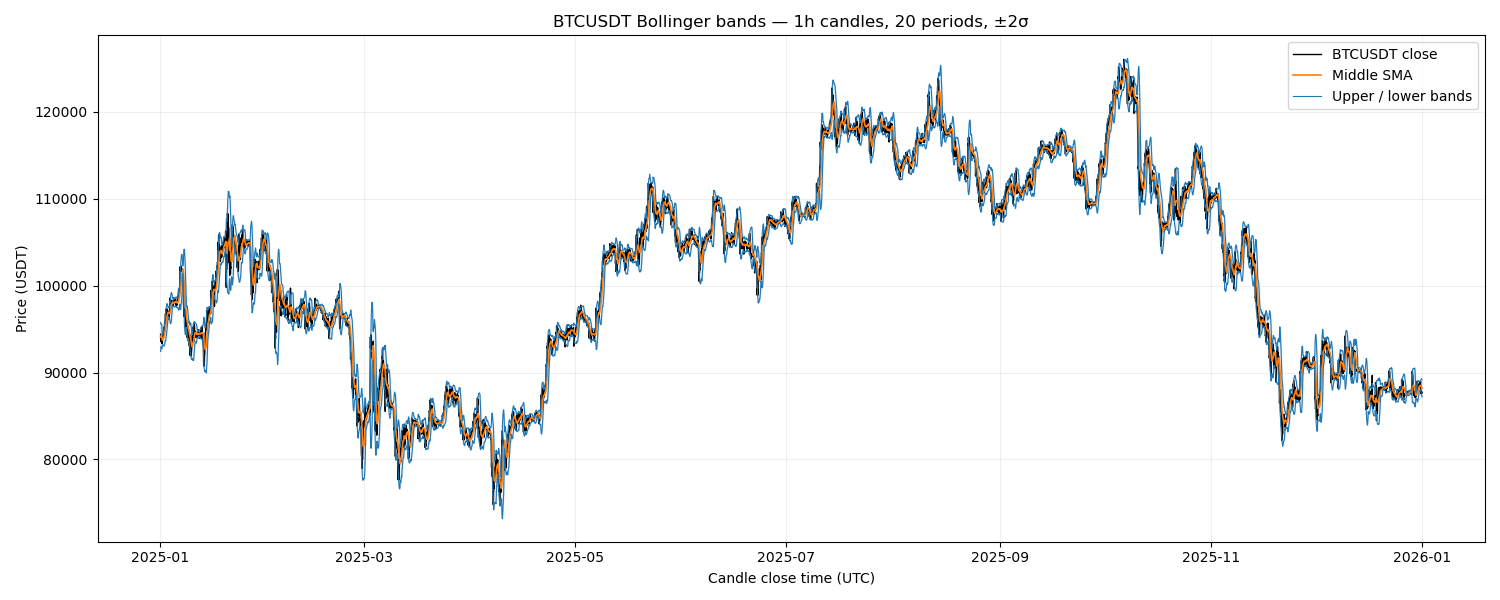

In [26]:
bb_daily = bollinger_bands(
    bars,
    start="2025-01-01",
    end="2026-01-01",
    resolution="1h",
    window=20,
    num_std=2,
)

fig, ax = plot_bollinger_bands(bb_daily)
plt.show()

In [27]:
def evaluate_band_rejections(bb):
    df = bb.sort_index().copy()
    step = pd.Timedelta(bb.attrs["resolution"])

    if df.index.has_duplicates:
        raise ValueError("Duplicate candle timestamps")

    # Reindex to preserve gaps: shift(1) must mean the previous
    # scheduled candle, not the previous available candle.
    full_index = pd.date_range(
        df.index.min(), df.index.max(), freq=step
    )
    df = df.reindex(full_index)
    df.index.name = "close_time_utc"

    df["known_lower"] = df["bb_lower"].shift(1)
    df["known_upper"] = df["bb_upper"].shift(1)

    valid = (
        df[[
            "open", "high", "low", "close",
            "known_lower", "known_upper",
        ]].notna().all(axis=1)
        & df["known_upper"].gt(df["known_lower"])
    )

    summaries = []
    event_frames = []

    for side in ["Support", "Resistance"]:
        support = side == "Support"
        level = df["known_lower"] if support else df["known_upper"]

        eligible = valid & (
            df["open"].gt(level) if support
            else df["open"].lt(level)
        )

        touched = eligible & (
            df["low"].le(level) if support
            else df["high"].ge(level)
        )

        opened_beyond = valid & (
            df["open"].lt(level) if support
            else df["open"].gt(level)
        )

        events = df.loc[touched, ["open", "high", "low", "close"]].copy()
        events["side"] = side
        events["level"] = level.loc[touched]

        # Positive = close returned to the expected side of the level.
        direction = 1 if support else -1
        events["close_distance_pct"] = (
            direction * 100 * (events["close"] / events["level"] - 1)
        )

        # Positive = price penetrated beyond the tested level.
        if support:
            events["penetration_pct"] = (
                100 * (events["level"] - events["low"]) / events["level"]
            )
        else:
            events["penetration_pct"] = (
                100 * (events["high"] - events["level"]) / events["level"]
            )

        events["outcome"] = np.select(
            [
                events["close_distance_pct"].gt(0),
                events["close_distance_pct"].lt(0),
            ],
            ["Rejected by close", "Broken by close"],
            default="Closed on level",
        )

        n = len(events)

        summaries.append({
            "side": side,
            "valid_candles": int(valid.sum()),
            "eligible_candles": int(eligible.sum()),
            "opened_beyond": int(opened_beyond.sum()),
            "tests": n,
            "rejections": int(events["outcome"].eq("Rejected by close").sum()),
            "breaks": int(events["outcome"].eq("Broken by close").sum()),
            "closed_on_level": int(events["outcome"].eq("Closed on level").sum()),
            "rejection_rate_pct": (
                100 * events["outcome"].eq("Rejected by close").mean()
                if n else np.nan
            ),
            "median_penetration_pct": events["penetration_pct"].median(),
            "median_close_distance_pct": events["close_distance_pct"].median(),
        })
        event_frames.append(events)

    summary = pd.DataFrame(summaries).set_index("side")
    events = pd.concat(event_frames).sort_index()

    return df, events, summary

In [28]:
band_review, band_events, band_summary = evaluate_band_rejections(bb_daily)

display(band_summary.round(3))
# display(band_events.head(10).round(3))

,valid_candles,eligible_candles,opened_beyond,tests,rejections,breaks,closed_on_level,rejection_rate_pct,median_penetration_pct,median_close_distance_pct
side,,,,,,,,,,
Support,8759,8198,561,897,456,441,0,50.836,0.211,0.007
Resistance,8759,8214,545,831,418,413,0,50.301,0.194,0.001


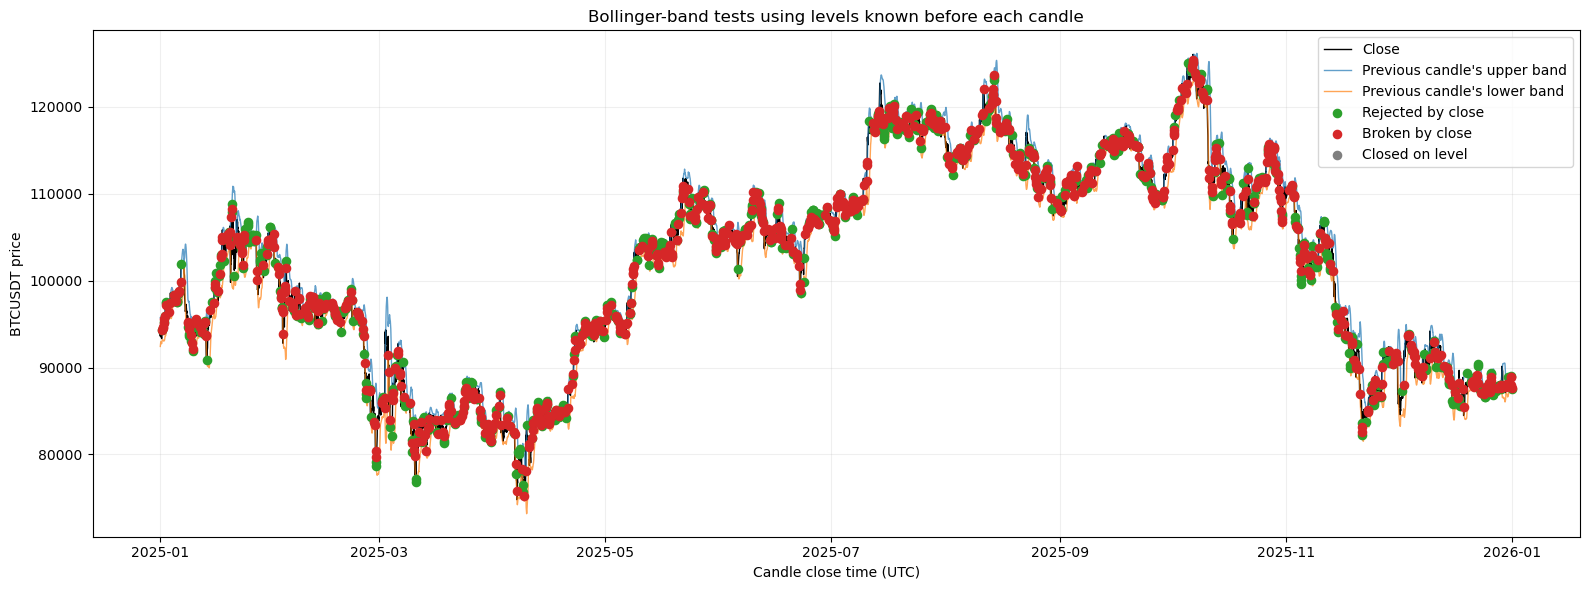

In [44]:
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    band_review.index, band_review["close"],
    color="black", linewidth=1, label="Close",
)

for column, label in [
    ("known_upper", "Previous candle's upper band"),
    ("known_lower", "Previous candle's lower band"),
]:
    ax.plot(
        band_review.index, band_review[column],
        linewidth=1, alpha=0.7, label=label,
    )

colors = {
    "Rejected by close": "tab:green",
    "Broken by close": "tab:red",
    "Closed on level": "tab:gray",
}

for outcome, color in colors.items():
    selected = band_events.loc[band_events["outcome"].eq(outcome)]
    ax.scatter(
        selected.index, selected["level"],
        color=color, s=35, zorder=5, label=outcome,
    )

ax.set_title("Bollinger-band tests using levels known before each candle")
ax.set_xlabel("Candle close time (UTC)")
ax.set_ylabel("BTCUSDT price")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

# E0 — Bollinger Event Study: Step 1

Determine how many distinct band-interaction episodes exist in the 1H data, without counting every candle in a prolonged band walk as a fresh event.

The implementation tracks both support and resistance separately.
Mechanism	Initial behavior
- Start	First eligible contact with the previously known band
- Anchor	Fixed band level at first contact
- Tracking	Count candles, contacts and maximum excursions
- Rearm	Return sufficiently inside the channel
- Timeout	Stop observing after 24 hourly candles
- Data end	Mark unfinished observations as right-censored
- Missing data	Censor the affected episode rather than bridge the gap

In [38]:
from episode_detector import detect_band_episodes, episode_summary

# Existing 1H Bollinger dataframe
bb = bollinger_bands(
    bars,
    start="2025-01-01",
    end="2026-01-01",
    resolution="15m",
    window=80,
    num_std=2.0,
)

print(f"Generated {len(bb)} hourly candles")
display(bb.tail())
episodes = detect_band_episodes(
    bb,
    rearm_pct_b=0.25,
    max_horizon=24,
)

display(episode_summary(episodes))
display(episodes.head(20))

Generated 35040 hourly candles


,open,high,low,close,volume,bb_middle,bb_upper,bb_lower
close_time_utc,,,,,,,,
2025-12-31 23:00:00+00:00,87733.98,87776.58,87656.19,87728.29,45.65187,88298.846000,89271.550547,87326.141453
2025-12-31 23:15:00+00:00,87728.30,87728.30,87656.29,87689.75,57.11681,88285.543625,89262.088909,87308.998341
2025-12-31 23:30:00+00:00,87689.76,87698.02,87619.67,87675.44,57.23590,88274.772500,89258.959047,87290.585953
2025-12-31 23:45:00+00:00,87675.44,87690.02,87650.27,87685.31,31.88983,88265.008375,89256.864356,87273.152394
2026-01-01 00:00:00+00:00,87685.31,87697.40,87641.14,87648.22,44.94869,88254.948125,89255.261603,87254.634647


,episodes,median_bars,total_contacts,rearmed,timeouts,right_censored,gap_censored
side,,,,,,,
Resistance,406,12.0,3441,300,106,0,0
Support,421,11.0,3594,316,105,0,0


,side,episode_id,start,anchor,n_bars,n_contacts,max_adverse_pct,max_favorable_pct,status,observation_end,rearm_time
0,Resistance,R0001,2025-01-01 14:15:00+00:00,94215.506226,2,2,0.249793,0.352220,REARMED,2025-01-01 14:30:00+00:00,2025-01-01 14:30:00+00:00
1,Resistance,R0002,2025-01-01 15:00:00+00:00,94211.864959,10,7,0.305837,0.373610,REARMED,2025-01-01 17:15:00+00:00,2025-01-01 17:15:00+00:00
2,Resistance,R0003,2025-01-01 19:00:00+00:00,94352.174891,24,19,0.898575,0.216036,TIMEOUT,2025-01-02 00:45:00+00:00,NaT
3,Resistance,R0004,2025-01-02 16:30:00+00:00,97297.655881,6,5,0.362130,0.990472,REARMED,2025-01-02 17:45:00+00:00,2025-01-02 17:45:00+00:00
4,Resistance,R0005,2025-01-02 19:30:00+00:00,97729.244603,9,1,0.112817,0.684263,REARMED,2025-01-02 21:30:00+00:00,2025-01-02 21:30:00+00:00
5,Support,S0001,2025-01-03 07:45:00+00:00,96338.843971,9,6,0.247910,0.374995,REARMED,2025-01-03 09:45:00+00:00,2025-01-03 09:45:00+00:00
6,Resistance,R0006,2025-01-03 15:45:00+00:00,97471.847125,24,21,1.544100,0.342363,TIMEOUT,2025-01-03 21:30:00+00:00,NaT
7,Support,S0002,2025-01-04 15:30:00+00:00,97632.334854,10,6,0.120395,0.532288,REARMED,2025-01-04 17:45:00+00:00,2025-01-04 17:45:00+00:00
8,Resistance,R0007,2025-01-04 19:30:00+00:00,98310.579142,2,1,0.040098,0.194281,REARMED,2025-01-04 19:45:00+00:00,2025-01-04 19:45:00+00:00
9,Resistance,R0008,2025-01-04 20:15:00+00:00,98311.327715,13,7,0.475126,0.171016,REARMED,2025-01-04 23:15:00+00:00,2025-01-04 23:15:00+00:00


In [37]:
nov = episodes.loc[
    (episodes["start"] >= "2025-11-01")
    & (episodes["start"] < "2025-12-01")
].copy()

display(
    nov.groupby(["side", "status"]).agg(
        episodes=("episode_id", "count"),
        median_bars=("n_bars", "median"),
        mean_contacts=("n_contacts", "mean"),
        max_bars=("n_bars", "max"),
    )
)

display(
    nov.loc[
        (nov["start"] >= "2025-11-13")
        & (nov["start"] < "2025-11-23"),
        [
            "side",
            "start",
            "observation_end",
            "n_bars",
            "n_contacts",
            "max_adverse_pct",
            "max_favorable_pct",
            "status",
        ],
    ]
)

,,episodes,median_bars,mean_contacts,max_bars
side,status,,,,
Resistance,REARMED,27,4.0,3.555556,20
Support,REARMED,36,5.0,3.916667,16


,side,start,observation_end,n_bars,n_contacts,max_adverse_pct,max_favorable_pct,status
615,Support,2025-11-13 17:00:00+00:00,2025-11-13 23:00:00+00:00,7,6,3.056081,0.446280,REARMED
616,Support,2025-11-14 05:00:00+00:00,2025-11-14 16:00:00+00:00,12,6,2.504318,2.257130,REARMED
617,Support,2025-11-14 21:00:00+00:00,2025-11-15 02:00:00+00:00,6,2,0.456266,1.584693,REARMED
618,Support,2025-11-15 21:00:00+00:00,2025-11-16 03:00:00+00:00,7,6,0.615497,0.610954,REARMED
619,Resistance,2025-11-16 10:00:00+00:00,2025-11-16 12:00:00+00:00,3,2,0.080522,1.095059,REARMED
620,Support,2025-11-16 16:00:00+00:00,2025-11-17 01:00:00+00:00,10,8,2.134793,0.561328,REARMED
621,Support,2025-11-17 17:00:00+00:00,2025-11-17 17:00:00+00:00,1,1,0.560651,0.901439,REARMED
622,Support,2025-11-17 18:00:00+00:00,2025-11-18 09:00:00+00:00,16,8,4.654201,0.837720,REARMED
623,Resistance,2025-11-18 16:00:00+00:00,2025-11-18 22:00:00+00:00,7,4,1.183050,1.864227,REARMED
624,Support,2025-11-19 06:00:00+00:00,2025-11-19 08:00:00+00:00,3,2,0.871941,1.334542,REARMED


### Step A — Compare actual durations

In [42]:
from e01_visualize import (
    episode_diagnostics,
    plot_episode_boundaries,
)

# For your 1H run
episodes_1h, stats_1h = episode_diagnostics(
    episodes, resolution="1h"
)

display(stats_1h)

,episodes,median_bars,median_duration_hours,max_duration_hours,median_contacts,timeouts,right_censored
side,,,,,,,
Resistance,406,12.0,12.0,24.0,6.0,106,0
Support,421,11.0,11.0,24.0,6.0,105,0


In [ ]:
from e01_visualize import (
    episode_diagnostics,
    plot_episode_boundaries,
)

episodes_15m, stats_15m = episode_diagnostics(
    episodes, resolution="15m"
)

display(stats_15m)

,episodes,median_bars,median_duration_hours,max_duration_hours,median_contacts,timeouts,right_censored
side,,,,,,,
Resistance,406,12.0,12.0,24.0,6.0,106,0
Support,421,11.0,11.0,24.0,6.0,105,0


### Step B — Visualize the November downtrend

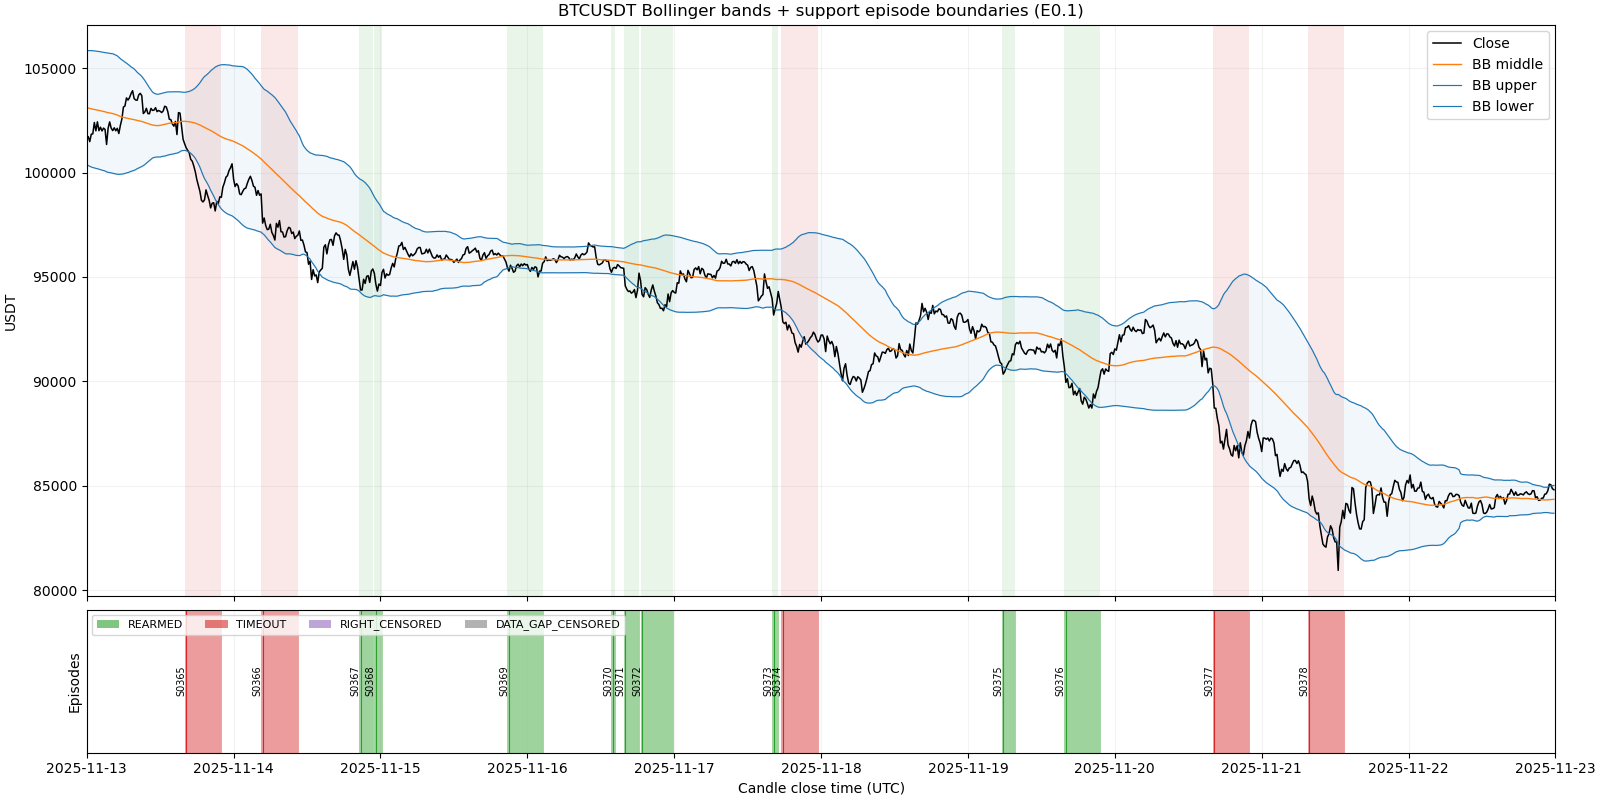

In [41]:
fig, axes, selected = plot_episode_boundaries(
    bb,
    episodes,
    start="2025-11-13",
    end="2025-11-23",
    side="Support",
    figsize=(16, 8),
)

plt.show()